# Raw to Bronze

## Remove columns with too many nulls

In [18]:
from pyspark.sql import functions as F, DataFrame
from pyspark.sql import SparkSession
from pyspark.sql.types import NumericType
import seaborn as sns
import matplotlib.pyplot as plt
from functools import reduce


spark = SparkSession.builder.getOrCreate()
table_path = "cloud_data_lake_prod.cds8_o2d_orders_raw_prod.cds8_bucket_o2d_orders_d2c"

raw = spark.read.table(table_path)
display(raw)
print(f"Total rows: {raw.count()}")
null_counts = raw.select(
    *[ 
        F.count(F.when(F.col(c).isNull(), 1)).alias(c+"_null_count")
        for c in raw.columns
    ]
)
display(null_counts)
raw = raw.drop("ppd_date", "ea_date", "fd_date", "pdd_date", "cdd_date", "add_date", "inv_in_date", "sow_date", "cdd2_date", "order_cancelled")

,chassino,prind,dstatus,distributorid,dealerid,pru,partperiod,producttype,orderdate,ppd_date,ea_date,fd_date,pdd_date,cdd_date,add_date,inv_in_date,sow_date,cdd2_date,countrycode,countryname,quotationid,order_cancelled,chassi_adap,tr_application,engine_type,cab_type,chassi_height,generation,wheel_conf5,wheel_conf6,montdeg,crd_date,gearbox,catwalk,ffu,cab_colour1,cab_colour2,fda,fpc_0771,fpc_2303,fpc_0514,fpc_6405,fpc_2471,fpc_6175,fpc_5005,fpc_3502,fpc_7023,fpc_3543,fpc_8932,history_ingestion_timestamp,raw_ingestion_timestamp,dl_import_timestamp
0,5494221,0009854734,Delivered,JP04,47648,N,17121,Truck,2017-04-17,2017-11-23,2017-11-23,2017-11-27,2018-01-23,2018-01-19,2018-01-18,2018-01-19,NaT,NaT,JP,Japan,QVPY7TYTZ,0.0,01163B,None,00408PC,00042G,00272B,01323E,00448R,None,A,20171128,00017TD,None,00780A,01503BH,01504C,7138.0,00771Z,02303H,None,None,02471J,None,None,03502Z,None,03543Z,None,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657
1,5475849,0009840156,Delivered,LT10,62711,N,17064,Truck,2017-03-23,2017-06-21,2017-06-21,2017-06-26,2017-07-03,2017-06-29,2017-06-28,2017-06-29,2017-09-21,NaT,LT,Lithuania,QLPM82FHS,0.0,01163B,None,00408PL,00042G,00272B,01323E,00448N,None,A,20170626,00017TC,None,00780A,01503ZO,01504B,6116.0,00771Z,02303E,00514B,None,02471J,None,None,03502Z,None,03543A,None,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657
2,5475925,0009840914,Delivered,D,61071,N,17064,Truck,2017-03-24,2017-06-22,2017-06-22,2017-07-04,2017-06-30,2017-07-07,2017-07-06,2017-07-07,2018-01-09,NaT,DE,Germany,QDE71636,0.0,01163B,None,00408NR,00042J,00272A,01323E,00448N,None,A,20170704,00017TG,None,00780A,01503ZO,01504B,2489.0,00771DA,02303Z,None,None,02471D,None,None,03502Z,None,03543A,None,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657
3,5476015,0009848499,Delivered,SGP13,27180,N,17064,Truck,2017-04-05,2017-06-22,2017-06-22,2017-06-27,2017-08-04,2017-08-26,2017-08-27,2017-08-23,2017-10-25,NaT,SG,Singapore,Q056B-17,0.0,01163B,None,00408NQ,00042G,00272C,01323E,00448C,None,A,20170627,00017TC,None,00780A,01503BH,01504C,7130.0,00771Z,02303Z,None,None,02471D,None,None,03502Z,None,03543Z,None,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657
4,5476015,0009848499,Delivered,SGP13,27180,N,17064,Truck,2017-04-05,2017-06-22,2017-06-22,2017-06-27,2017-08-04,2017-08-26,2017-08-27,2017-08-23,2017-10-25,NaT,SG,Singapore,Q056B-17,0.0,01163B,None,00408NQ,00042G,00272C,01323E,00448C,None,A,20170627,00017TC,None,00780A,01503BH,01504C,7130.0,00771Z,02303Z,None,None,02471D,None,None,03502Z,None,03543Z,None,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657
5,5476015,0009848499,Delivered,SGP13,27180,N,17064,Truck,2017-04-05,2017-06-22,2017-06-22,2017-06-27,2017-08-04,2017-08-26,2017-08-27,2017-08-23,2017-10-25,NaT,SG,Singapore,Q056B-17,0.0,01163B,None,00408NQ,00042G,00272C,01323E,00448C,None,A,20170627,00017TC,None,00780A,01503BH,01504C,7130.0,00771Z,02303Z,None,None,02471D,None,None,03502Z,None,03543Z,None,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657
6,5476015,0009848499,Delivered,SGP13,27180,N,17064,Truck,2017-04-05,2017-06-22,2017-06-22,2017-06-27,2017-08-04,2017-08-26,2017-08-27,2017-08-23,2017-10-25,NaT,SG,Singapore,Q056B-17,0.0,01163B,None,00408NQ,00042G,00272C,01323E,00448C,None,A,20170627,00017TC,None,00780A,01503BH,01504C,7130.0,00771Z,02303Z,None,None,02471D,None,None,03502Z,None,03543Z,None,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657
7,5476015,0009848499,Delivered,SGP13,27180,N,17064,Truck,2017-04-05,2017-06-22,2017-06-22,2017-06-27,2017-08-04,2017-08-26,2017-08-27,2017-08-23,2017-10-25,NaT,SG,Singapore,Q056B-17,0.0,01163B,None,00408NQ,00042G,00272C,01323E,00448C,None,A,20170627,00017TC,None,00780A,01503BH,01504C,7130.0,00771Z,02303Z,None,None,02471D,None,None,03502Z,None,03543Z,None,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657,2024-01-21 00:15:13.657
8,5476015,0009848499,Delivered

Total rows: 908453


,chassino_null_count,prind_null_count,dstatus_null_count,distributorid_null_count,dealerid_null_count,pru_null_count,partperiod_null_count,producttype_null_count,orderdate_null_count,ppd_date_null_count,ea_date_null_count,fd_date_null_count,pdd_date_null_count,cdd_date_null_count,add_date_null_count,inv_in_date_null_count,sow_date_null_count,cdd2_date_null_count,countrycode_null_count,countryname_null_count,quotationid_null_count,order_cancelled_null_count,chassi_adap_null_count,tr_application_null_count,engine_type_null_count,cab_type_null_count,chassi_height_null_count,generation_null_count,wheel_conf5_null_count,wheel_conf6_null_count,montdeg_null_count,crd_date_null_count,gearbox_null_count,catwalk_null_count,ffu_null_count,cab_colour1_null_count,cab_colour2_null_count,fda_null_count,fpc_0771_null_count,fpc_2303_null_count,fpc_0514_null_count,fpc_6405_null_count,fpc_2471_null_count,fpc_6175_null_count,fpc_5005_null_count,fpc_3502_null_count,fpc_7023_null_count,fpc_3543_null_count,fpc_8932_null_count,history_ingestion_timestamp_null_count,raw_ingestion_timestamp_null_count,dl_import_timestamp_null_count
0,0,0,0,0,0,0,0,0,0,4735,777,855,6864,6586,180941,12797,63893,700040,0,0,0,20475,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## Remove columns with too many categories

In [ ]:
type_counts = raw.agg(*[
    F.countDistinct(F.col(c)).alias(c)
    for c in raw.columns
])
display(type_counts)
raw = raw.drop("chassino", "prind", "quotationid", "fda", "history_ingestion_timestamp", "raw_ingestion_timestamp", "dl_import_timestamp")

,chassino,prind,dstatus,distributorid,dealerid,pru,partperiod,producttype,orderdate,countrycode,countryname,quotationid,chassi_adap,tr_application,engine_type,cab_type,chassi_height,generation,wheel_conf5,wheel_conf6,montdeg,crd_date,gearbox,catwalk,ffu,cab_colour1,cab_colour2,fda,fpc_0771,fpc_2303,fpc_0514,fpc_6405,fpc_2471,fpc_6175,fpc_5005,fpc_3502,fpc_7023,fpc_3543,fpc_8932,history_ingestion_timestamp,raw_ingestion_timestamp,dl_import_timestamp
0,868861,868878,6,218,1426,6,712,1,3800,124,124,375869,4,39,163,7,7,5,19,20,3,2742,40,11,5,185,8,7340,106,21,10,11,13,139,26,6,4,5,2,1,1,1


c:\Users\ayu0ue\github\CDS_practicing\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1134: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Categorical columns: 38; heatmap matrix: 38 x 38


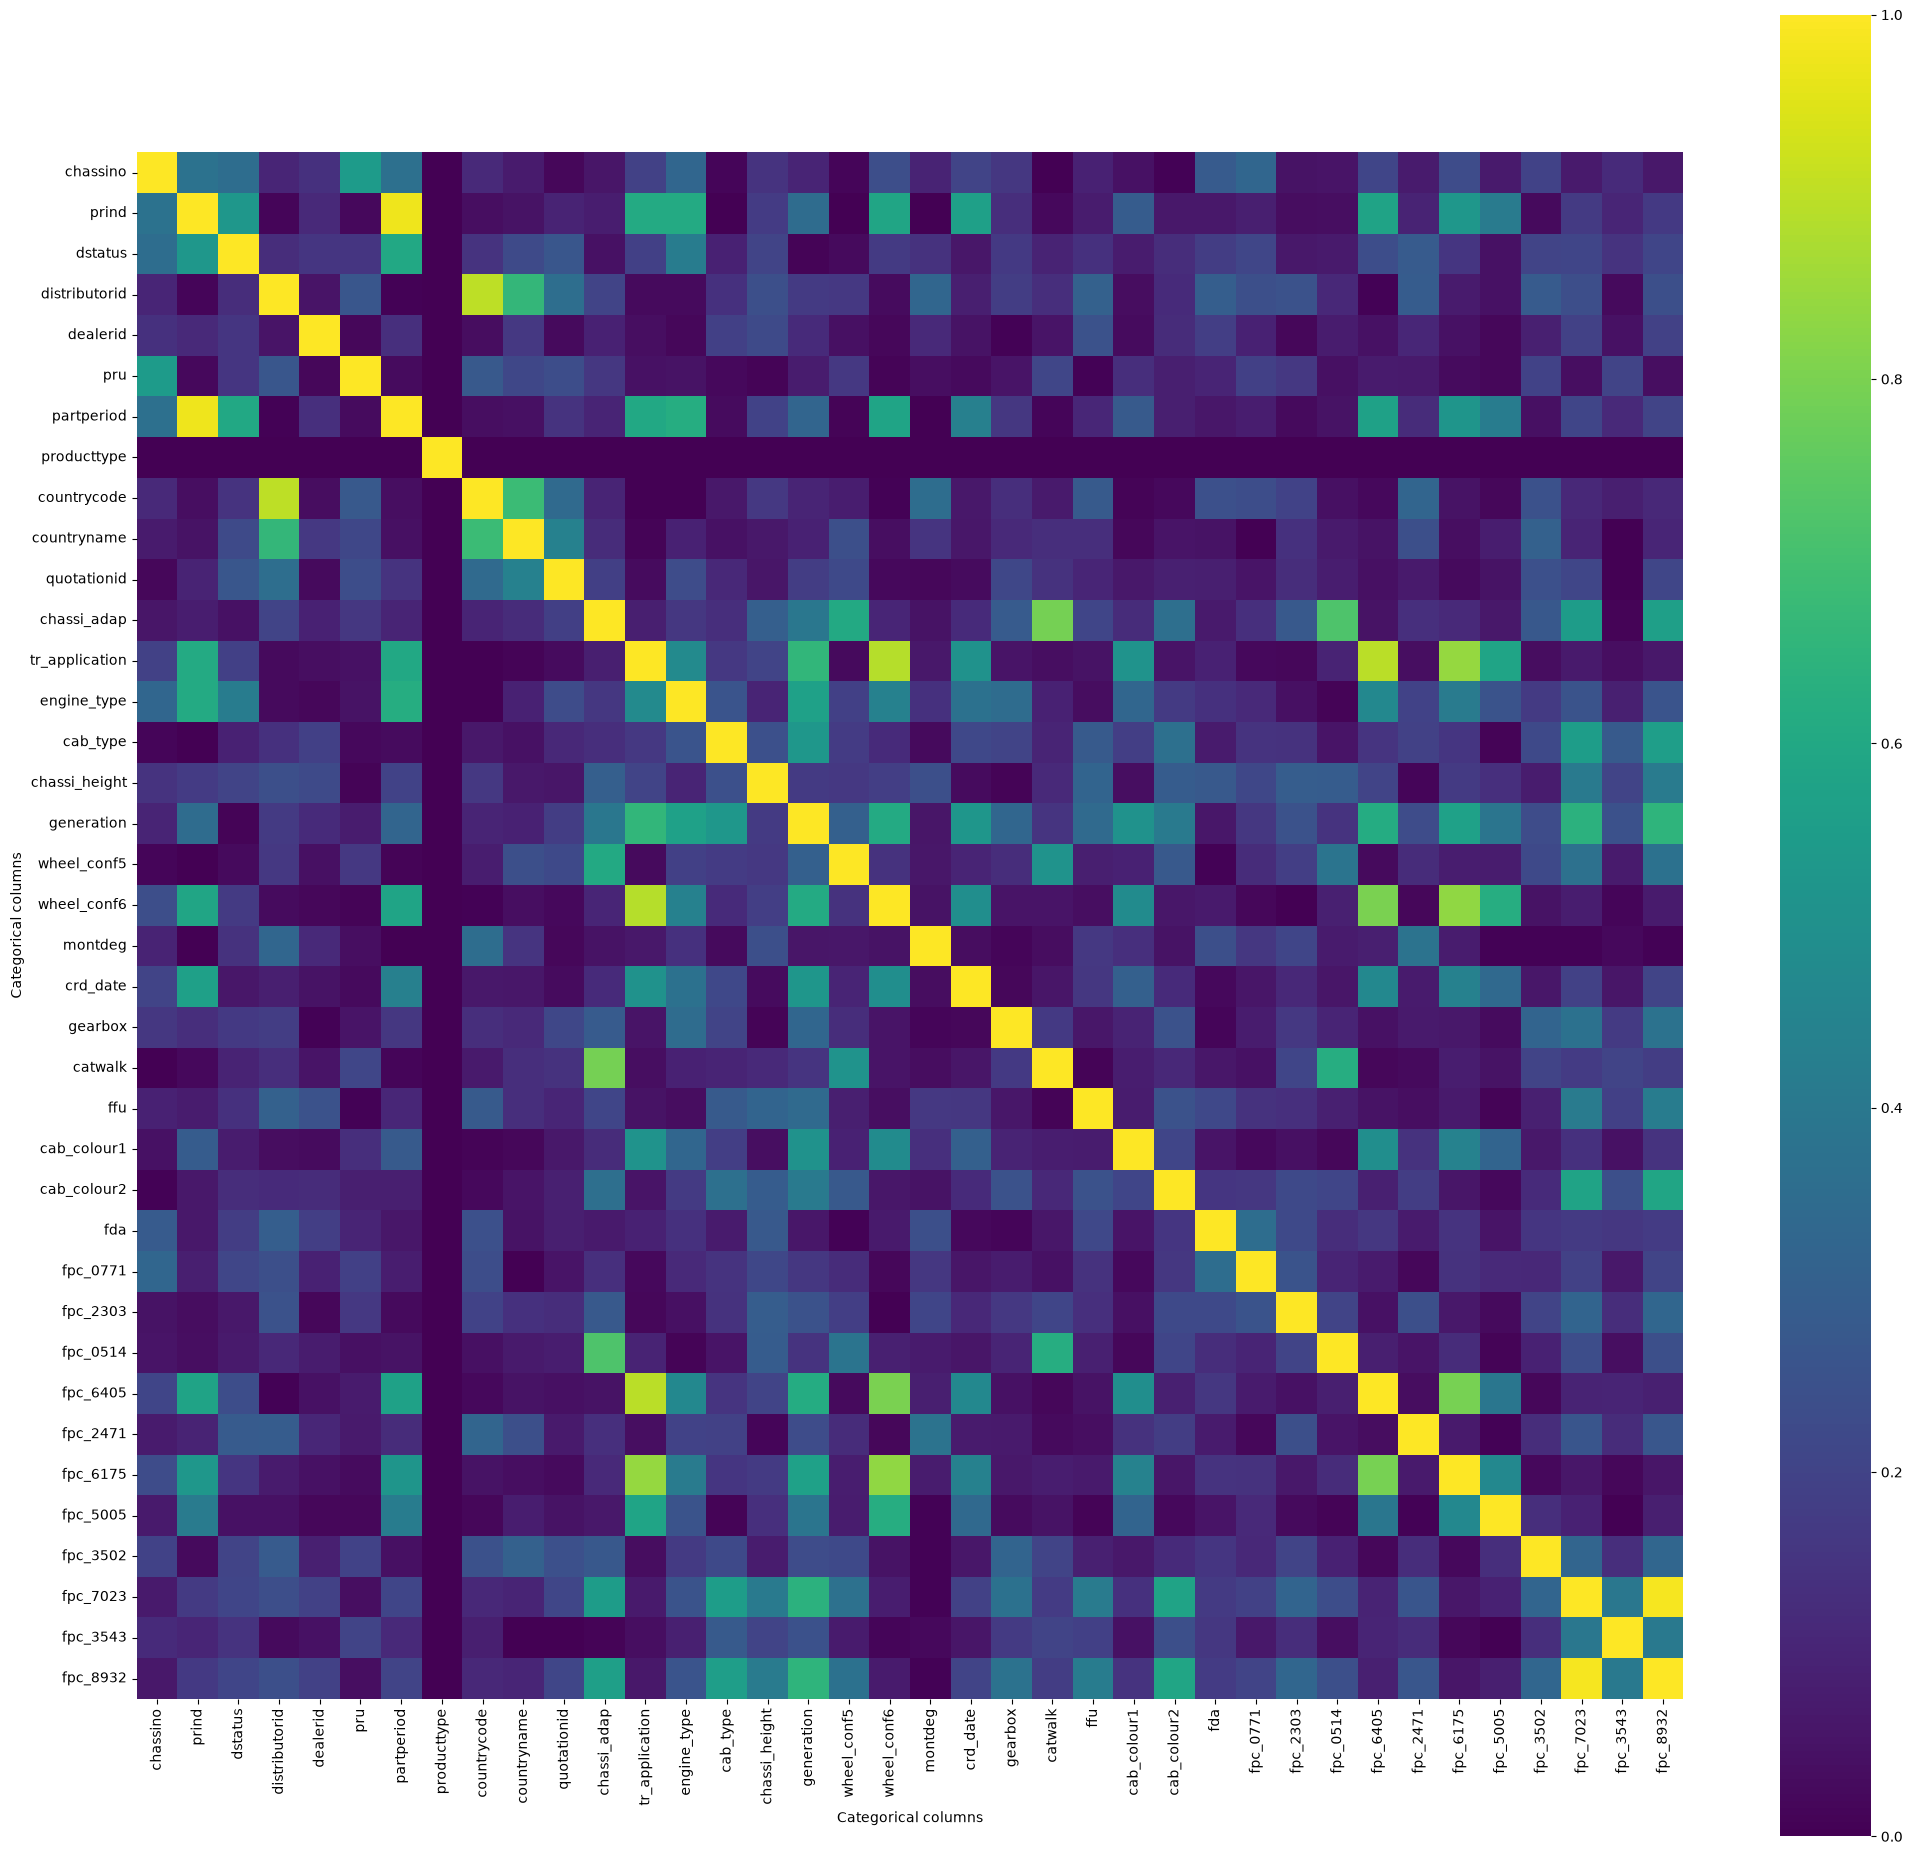

In [8]:
import pandas as pd
from pyspark.sql.types import StringType
from pyspark.sql.window import Window
import seaborn as sns
import matplotlib.pyplot as plt

# Encode string categories with Spark SQL windows; this also works without a JVM SparkContext.
categorical_cols = [f.name for f in raw.schema.fields if isinstance(f.dataType, StringType)]
sample_size = 5000
sample_df = raw.select(*categorical_cols).sample(withReplacement=False, fraction=0.01, seed=42).limit(sample_size)

encoded_cols = [f"{c}_encoded" for c in categorical_cols]
encoded_exprs = [
    (F.dense_rank().over(Window.orderBy(F.col(c))) - 1)
        .cast("int").alias(f"{c}_encoded")
    for c in categorical_cols
]
encoded_sample = sample_df.select(*encoded_exprs).toPandas()

# Correlate the encoded columns and relabel axes with their original categorical column names.
values = pd.DataFrame(encoded_sample)
values.columns = categorical_cols
corr = values.corr().abs()
print(f"Categorical columns: {len(categorical_cols)}; heatmap matrix: {corr.shape[0]} x {corr.shape[1]}")
if corr.shape != (len(categorical_cols), len(categorical_cols)):
    raise ValueError("Expected one heatmap row and column per categorical column.")

# Constant encoded columns have undefined correlations (NaN); keep their axes, color undefined values as 0.
corr = corr.fillna(0)
for i in range(len(categorical_cols)):
    corr.iat[i, i] = 1.0

n_cols = len(categorical_cols)
plt.figure(figsize=(max(12, n_cols * 0.55), max(10, n_cols * 0.5)))
sns.heatmap(corr, cmap="viridis", vmin=0, vmax=1, square=True,
            xticklabels=True, yticklabels=True)
plt.xticks(rotation=90)
plt.xlabel("Categorical columns")
plt.ylabel("Categorical columns")
plt.tight_layout()
plt.show()
# n_rows, n_cols = values.shape
# association = np.eye(n_cols, dtype=float)
# for i in range(n_cols):
#     x = values[:, i]
#     x_counts = np.bincount(x)
#     for j in range(i + 1, n_cols):
#         y = values[:, j]
#         y_counts = np.bincount(y)
#         dof = min(len(x_counts) - 1, len(y_counts) - 1)
#         if dof <= 0 or n_rows == 0:
#             v = 0.0
#         else:
#             pairs, pair_counts = np.unique(np.column_stack((x, y)), axis=0, return_counts=True)
#             chi2 = np.sum(pair_counts ** 2 * n_rows / (x_counts[pairs[:, 0]] * y_counts[pairs[:, 1]])) - n_rows
#             v = np.sqrt(max(chi2, 0.0) / (n_rows * dof))
#         association[i, j] = association[j, i] = v

# plt.figure(figsize=(max(10, n_cols * 0.45), max(8, n_cols * 0.4)))
# sns.heatmap(association, cmap="viridis", vmin=0, vmax=1, square=True,
#             xticklabels=categorical_cols, yticklabels=categorical_cols)
# plt.title("Categorical column association (Cramer's V)")
# plt.xlabel("Categorical columns")
# plt.ylabel("Categorical columns")
# plt.tight_layout()
# plt.show()

Databricks Connect client: 18.0.9
Remote Spark version: 4.2.0


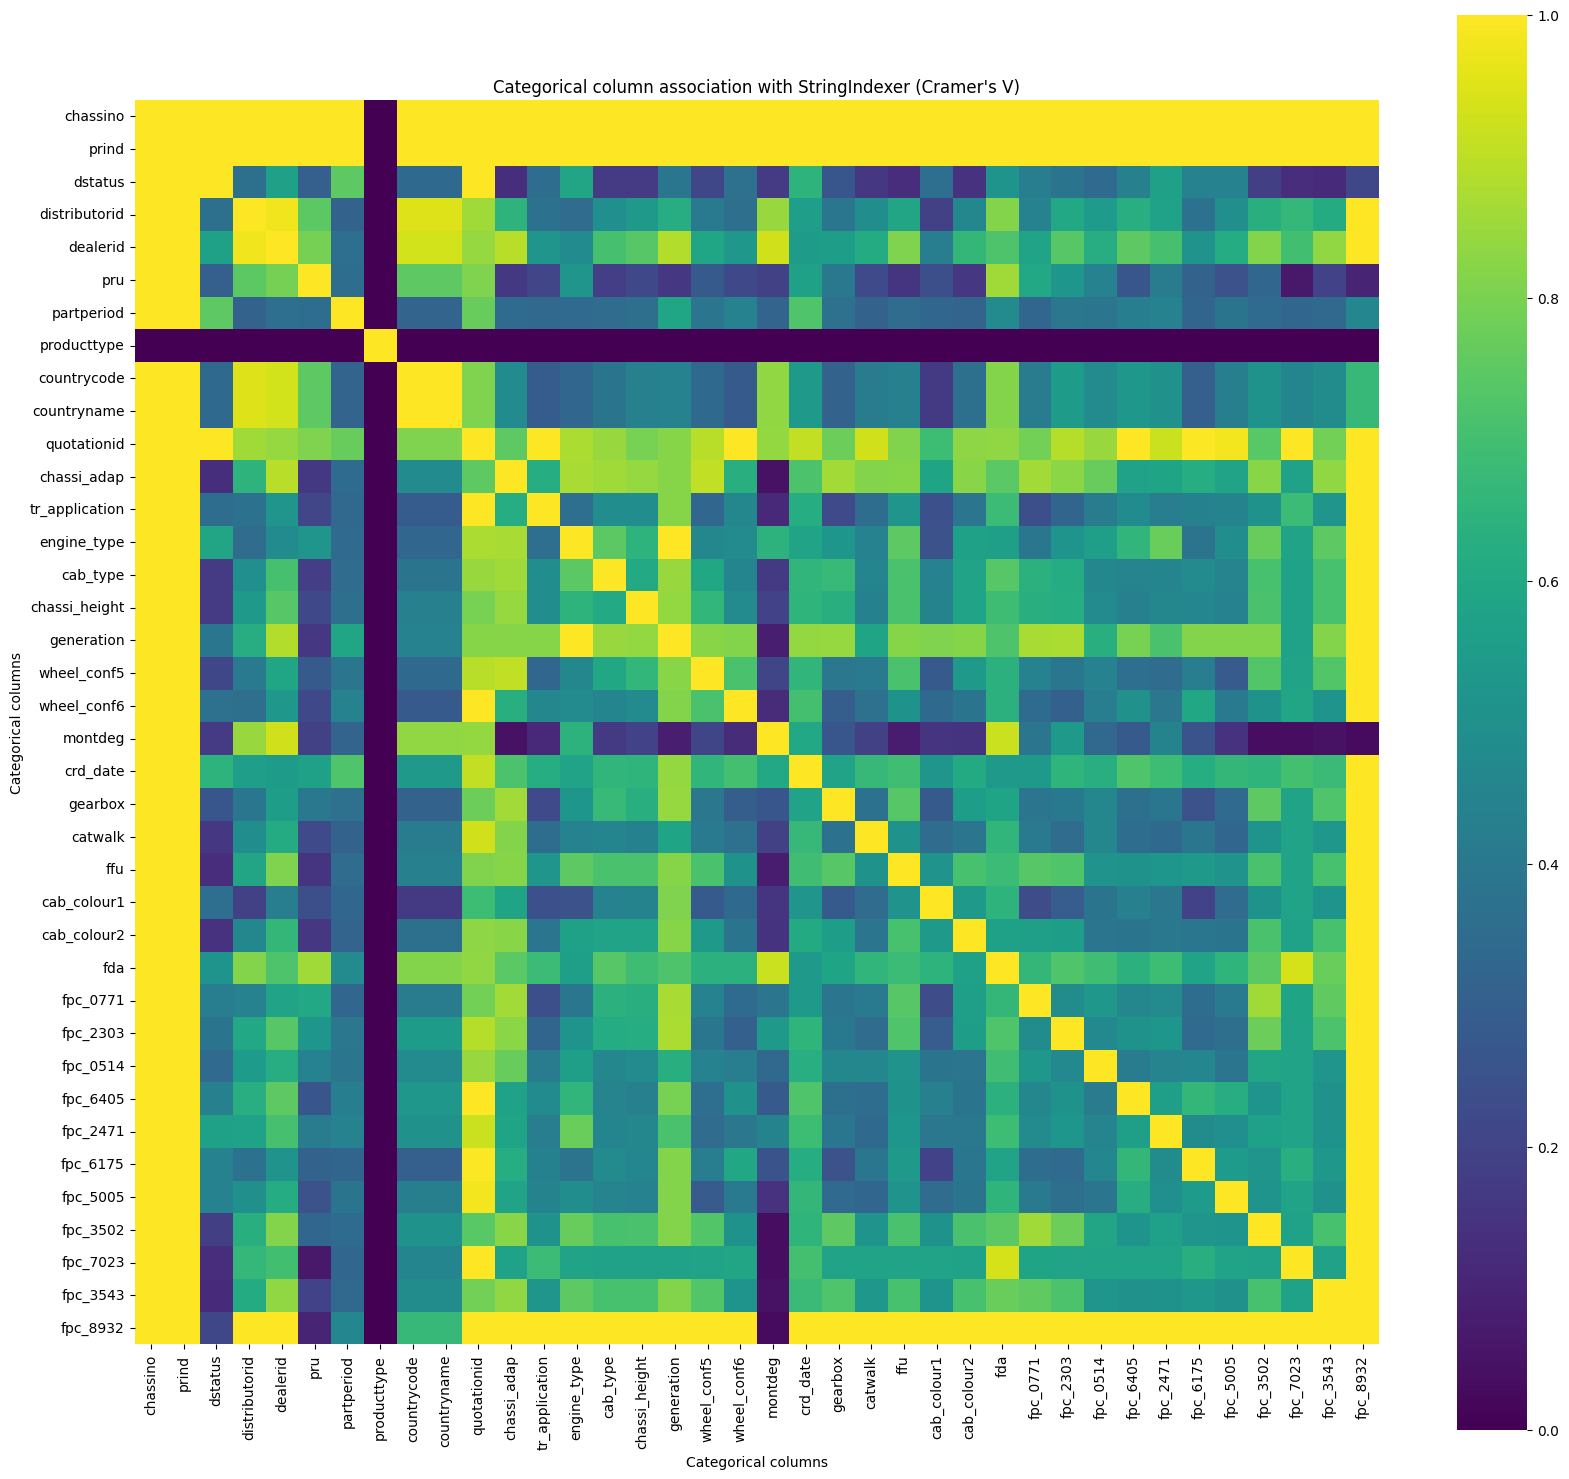

In [ ]:
# Alternative using pyspark.ml.feature.StringIndexer over Spark Connect.
# The Connect client and the remote Databricks compute must both support Spark ML.
from importlib.metadata import version as package_version
import numpy as np
from pyspark.ml.feature import StringIndexer
from pyspark.sql.types import StringType

categorical_cols = [f.name for f in raw.schema.fields if isinstance(f.dataType, StringType)]
sample_df = raw.select(*categorical_cols).sample(withReplacement=False, fraction=0.01, seed=42).limit(5000)
encoded_cols = [f"{c}_encoded" for c in categorical_cols]
server_spark_version = spark.version

indexer = StringIndexer(
    inputCols=categorical_cols,
    outputCols=encoded_cols,
    handleInvalid="keep"
)
indexer_model = indexer.fit(sample_df)


encoded_sample_ml = indexer_model.transform(sample_df).select(*encoded_cols).toPandas()
values = encoded_sample_ml.to_numpy(dtype=np.int64)
n_rows, n_cols = values.shape
association_ml = np.eye(n_cols, dtype=float)
for i in range(n_cols):
    x = values[:, i]
    x_counts = np.bincount(x)
    for j in range(i + 1, n_cols):
        y = values[:, j]
        y_counts = np.bincount(y)
        dof = min(len(x_counts) - 1, len(y_counts) - 1)
        if dof <= 0 or n_rows == 0:
            v = 0.0
        else:
            pairs, pair_counts = np.unique(np.column_stack((x, y)), axis=0, return_counts=True)
            chi2 = np.sum(pair_counts ** 2 * n_rows / (x_counts[pairs[:, 0]] * y_counts[pairs[:, 1]])) - n_rows
            v = np.sqrt(max(chi2, 0.0) / (n_rows * dof))
        association_ml[i, j] = association_ml[j, i] = v
plt.figure(figsize=(max(10, n_cols * 0.45), max(8, n_cols * 0.4)))
sns.heatmap(association_ml, cmap="viridis", vmin=0, vmax=1, square=True,
            xticklabels=categorical_cols, yticklabels=categorical_cols)
plt.title("Categorical column association with StringIndexer (Cramer's V)")
plt.xlabel("Categorical columns")
plt.ylabel("Categorical columns")
plt.tight_layout()
plt.show()